In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [3]:
df = pd.read_csv('Wine.csv')

In [4]:
print("First 5 Records : ")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nColumn Names")
print(df.columns)

print("\nDataset Information")
print(df.info())

print("\nDataset Description : ")
print(df.describe())

First 5 Records : 
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1

In [5]:
print("\nMissing Values: ")
print(df.isnull().sum())


Missing Values: 
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64


In [6]:
x = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("\nNumber of Input Features: ", x.shape[1])
print("\nNumber of Classes: ", y.nunique())

print("\nClasses: ")
print(y.unique())


Number of Input Features:  13

Number of Classes:  3

Classes: 
[1 2 3]


In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)

In [8]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [9]:
print("Model Using Original Features : ")

model_original = LogisticRegression(max_iter = 1000)
model_original.fit(x_train_scaled, y_train)
y_pred_original = model_original.predict(x_test_scaled)
accuracy_original = accuracy_score(y_test, y_pred_original)

print("\nNumber of Original Features:",x_train_scaled.shape[1])
print("\nAccuracy: ", accuracy_original)

Model Using Original Features : 

Number of Original Features: 13

Accuracy:  0.9722222222222222


In [10]:
print("Dimensionality Reduction using PCA : ")
pca = PCA(n_components=2)
x_train_pca = pca.fit_transform(x_train_scaled)
x_test_pca = pca.transform(x_test_scaled)

print("\nOriginal Number of Featured:",x_train_scaled.shape[1])
print("Number of Principal Components:", x_train_pca.shape[1])

print("\nVariance Explained by Principal Components : ")
print(pca.explained_variance_ratio_)
print("\nTotal Variance Explained:")
print(sum(pca.explained_variance_ratio_))

model_pca = LogisticRegression(max_iter = 1000)
model_pca.fit(x_train_pca, y_train)
y_pred_pca = model_pca.predict(x_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
print("\nAccuracy: ", accuracy_pca)

Dimensionality Reduction using PCA : 

Original Number of Featured: 13
Number of Principal Components: 2

Variance Explained by Principal Components : 
[0.35792104 0.19270671]

Total Variance Explained:
0.5506277578733126

Accuracy:  0.9166666666666666


In [11]:
lda = LinearDiscriminantAnalysis(n_components=2)
x_train_lda = lda.fit_transform(x_train_scaled, y_train)
x_test_lda = lda.transform(x_test_scaled)

print("\nOriginal Number of Featured:",x_train_scaled.shape[1])
print("Number of Linear Discriminants:", x_train_lda.shape[1])

model_lda = LogisticRegression(max_iter = 1000)
model_lda.fit(x_train_lda, y_train)
y_pred_lda = model_lda.predict(x_test_lda)

accuracy_score_lda = accuracy_score(y_test, y_pred_lda)
print("\nAccuracy: ", accuracy_score_lda)


Original Number of Featured: 13
Number of Linear Discriminants: 2

Accuracy:  0.9722222222222222


In [12]:
results = pd.DataFrame({
    'Method': ['Original Features', 'PCA', 'LDA'],
    'Number of Features': [x_train_scaled.shape[1], x_train_pca.shape[1], x_train_lda.shape[1]],
    'Accuracy': [accuracy_original, accuracy_pca, accuracy_score_lda]
})

print(results)


              Method  Number of Features  Accuracy
0  Original Features                  13  0.972222
1                PCA                   2  0.916667
2                LDA                   2  0.972222


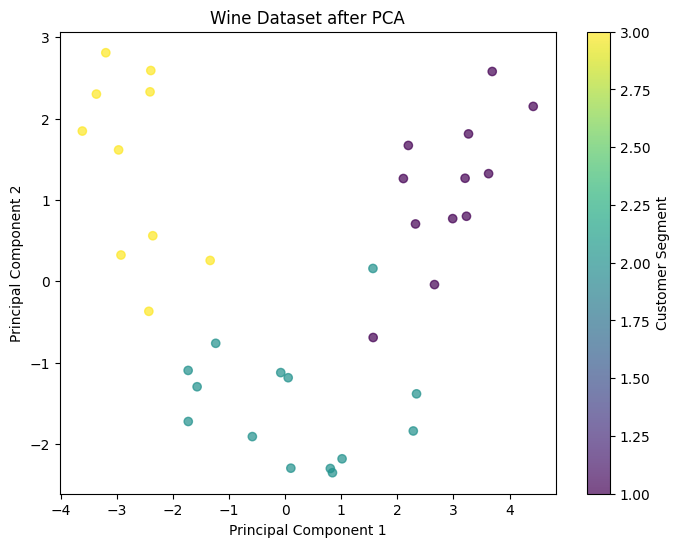

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(
  x_test_pca[:, 0],
  x_test_pca[:, 1],
  c=y_test,
  alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset after PCA")
plt.colorbar(
label="Customer Segment"
)
plt.show()

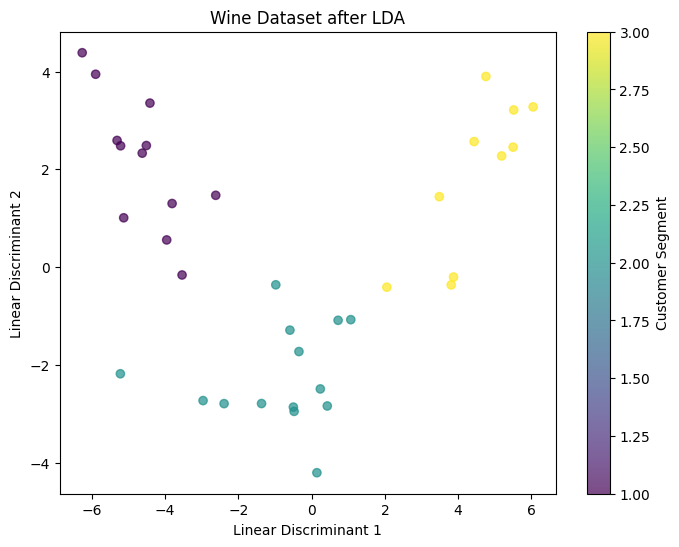

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(
  x_test_lda[:, 0],
  x_test_lda[:, 1],
  c=y_test,
  alpha=0.7
)
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("Wine Dataset after LDA")
plt.colorbar(
  label="Customer Segment"
)
plt.show()

In [15]:
print(classification_report(y_test, y_pred_original))
print(classification_report(y_test,y_pred_pca))
print(classification_report(y_test,y_pred_lda))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

              precision    recall  f1-score   support

           1       0.92      0.92      0.92        12
           2       0.87      0.93      0.90        14
           3       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy        